<img src="https://www.th-koeln.de/img/logo.svg" style="float:right;" width="200">

# 6th exercise: <font color="#C70039">Work with Autoencoders for anomaly detection</font>
* Course: AML
* Lecturer: <a href="https://www.gernotheisenberg.de/">Gernot Heisenberg</a>
* Author of notebook: <a href="https://www.gernotheisenberg.de/">Gernot Heisenberg</a>
* Date:   15.11.2026
* Student Name : Mohammed Suhan, Mohammed Suhan
* Matriculation No. : 11707086
<img src="https://blog.keras.io/img/ae/autoencoder_schema.jpg" style="float: center;" width="700">

---------------------------------
**GENERAL NOTE 1**: 
Please make sure you are reading the entire notebook, since it contains a lot of information on your tasks (e.g. regarding the set of certain parameters or a specific computational trick), and the written mark downs as well as comments contain a lot of information on how things work together as a whole. 

**GENERAL NOTE 2**: 
* Please, when commenting source code, just use English language only. 
* When describing an observation please use English language, too.
* This applies to all exercises throughout this course.

---------------------------------

### <font color="ce33ff">DESCRIPTION</font>:
Autoencoder is an unsupervised artificial neural network (ANN) that learns how to efficiently compress and encode data and then learns how to reconstruct the data back from the reduced encoded representation to a representation that is as close to the original input as possible.

An Autoencoder reduces data dimensions by learning how to ignore the noise in the data and thus outliers.
In the section above, you can seen an example of the input/output image from the MNIST dataset to an Autoencoder.

#### Autoencoder Components:
An Autoencoder consists of four main parts:

1. Encoder: In which the model learns how to reduce the input dimensions and compress the input data into an encoded representation.

2. Bottleneck: which is the layer that contains the compressed representation of the input data. This is the lowest possible dimensions of the input data. The bottlneck is also called latent vector. The concept of the latent space and latent vectors becomes important later on as we move forward to understand Generative Models. 

3. Decoder: In which the model learns how to reconstruct the data from the encoded representation to be as close to the original input as possible.

4. Reconstruction Loss: This is the method that measures how well the decoder is performing and how close the output is to the original input.

As always in ANNs, the training itself involves back propagation in order to minimize the network’s reconstruction loss.

Due to this features of an Autoencoder the use cases are manyfold. One of the obviously is anomaly detection. 

#### Autoencoder Architecture:

The network architecture for Autoencoders can vary between simple Feed Forward networks, Recurrent Neural Networks (LSTM) or Convolutional Neural Networks (CNN) depending on the use case. 

---------------------------------

### <font color="FFC300">TASKS</font>:
The tasks that you need to work on within this notebook are always indicated below as bullet points. 
If a task is more challenging and consists of several steps, this is indicated as well. 
Make sure you have worked down the task list and commented your doings. 
This should be done by using markdown.<br> 
<font color=red>Make sure you don't forget to specify your name and your matriculation number in the notebook.</font>

**YOUR TASKS in this exercise are as follows**:
1. import the notebook to Google Colab or use your local machine.
2. make sure you specified your name and your matriculation number in the header below my name and date. 
    * set the date too and remove mine.
3. read the entire notebook carefully 
    * add comments wherever you feel it necessary for better understanding
    * run the notebook for the first time.
    * the example below shows how to use an autoencoder for anomaly detection

4. <font color=green>Develop an Autoencoder for Domain Adaptation (Me -> Walter White ). You can of course also take own data, e.g. a photo of yours and someone else.</font>
5. Use shuffled mini-batches, choose a justified epoch limit, and monitor the reconstruction loss to avoid unnecessary training.
6. Implement a CNN for working out important features for the adaptation. If you feel lost in the exercise, please visit the sample solution.
7. There is also an implementation of data augmentation that helps you building up your data set from one single "original" image. 
---------------------------------

### Auto-Encoding
If you have correlated input data, the auto-encoder method will work very well because the encoding operation relies on the correlated features to compress the data.
Let’s consider that an auto-encoder is trained on the MNIST dataset. 
As you know already, using a simple FeedForward neural network, this can be done by building a simple 6 layers network as below:

In [1]:
# Train the network to reconstruct MNIST images, not to predict their digit labels.
# The small bottleneck forces the autoencoder to keep only essential image information.
import numpy as np
import torch
from pathlib import Path
from urllib.request import urlretrieve
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import functional as TF
from torchvision.transforms import v2

torch.manual_seed(1)
# Use an NVIDIA GPU, Mac GPU or CPU, whichever is available
device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available()
                      else "cpu")
print("Using device:", device)

# Load MNIST as normalized tensors in the interval [0, 1].
tensor_transform = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
mnist_train = datasets.MNIST(root="./data", train=True, download=True, transform=tensor_transform)
mnist_test = datasets.MNIST(root="./data", train=False, download=True, transform=tensor_transform)
train_loader = DataLoader(mnist_train, batch_size=1_024, shuffle=True)
validation_loader = DataLoader(mnist_test, batch_size=1_024, shuffle=False)


class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 512),
            nn.ELU(),
            nn.Linear(512, 128),
            nn.ELU(),
            nn.Linear(128, 10),
        )
        self.decoder = nn.Sequential(
            nn.Linear(10, 128),
            nn.ELU(),
            nn.Linear(128, 512),
            nn.ELU(),
            nn.Linear(512, 784),
            nn.Sigmoid(),
        )

    def forward(self, inputs):
        return self.decoder(self.encoder(inputs))


autoencoder = Autoencoder().to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(autoencoder.parameters())
history = {"training_loss": [], "validation_loss": []}

for epoch in range(10):
    autoencoder.train()
    training_loss = 0.0
    for images, _ in train_loader:
        images = images.to(device)
        optimizer.zero_grad()
        reconstructions = autoencoder(images)
        loss = criterion(reconstructions, images.flatten(start_dim=1))
        loss.backward()
        optimizer.step()
        training_loss += loss.item() * images.size(0)

    autoencoder.eval()
    validation_loss = 0.0
    with torch.inference_mode():
        for images, _ in validation_loader:
            images = images.to(device)
            reconstructions = autoencoder(images)
            validation_loss += criterion(reconstructions, images.flatten(start_dim=1)).item() * images.size(0)

    training_loss /= len(mnist_train)
    validation_loss /= len(mnist_test)
    history["training_loss"].append(training_loss)
    history["validation_loss"].append(validation_loss)
    print(f"Epoch {epoch + 1:02d}: train={training_loss:.5f}, validation={validation_loss:.5f}")

# The encoder and decoder are available as autoencoder.encoder and autoencoder.decoder.

Using device: mps
Epoch 01: train=0.08064, validation=0.06062
Epoch 02: train=0.05317, validation=0.04486
Epoch 03: train=0.03870, validation=0.03379
Epoch 04: train=0.03086, validation=0.02766
Epoch 05: train=0.02625, validation=0.02418
Epoch 06: train=0.02364, validation=0.02230
Epoch 07: train=0.02204, validation=0.02101
Epoch 08: train=0.02086, validation=0.02004
Epoch 09: train=0.01996, validation=0.01938
Epoch 10: train=0.01923, validation=0.01863


The validation reconstruction loss should decrease as training progresses. An autoencoder trained only on MNIST digits generally reconstructs in-distribution digits better than unrelated images. For anomaly detection, compare per-image reconstruction errors and derive a threshold from held-out normal data instead of relying on a fixed value from one run.

#### Autoencoders for anomaly detection
The following cells compute the mean squared reconstruction error for a held-out MNIST image and for two external images. All images are normalized to the same `[0, 1]` range before comparison. The 99th percentile of the validation errors is used as a transparent example threshold.

In [2]:
# Calculate an individual reconstruction error for every image in a batch.
# A validation quantile provides a data-driven example threshold for anomalies.
def reconstruction_errors(images):
    autoencoder.eval()
    images = images.to(device)
    with torch.inference_mode():
        reconstructions = autoencoder(images)
    targets = images.flatten(start_dim=1)
    return torch.mean((targets - reconstructions) ** 2, dim=1).cpu()


# Estimate an anomaly threshold from held-out normal observations.
validation_errors = []
for images, _ in validation_loader:
    validation_errors.append(reconstruction_errors(images))
validation_errors = torch.cat(validation_errors)
anomaly_threshold = torch.quantile(validation_errors, 0.99).item()

input_image, _ = mnist_test[50]
mnist_error = reconstruction_errors(input_image.unsqueeze(0)).item()
print(f"MNIST reconstruction error: {mnist_error:.6f}")
print(f"Example 99th-percentile threshold: {anomaly_threshold:.6f}")

MNIST reconstruction error: 0.007118
Example 99th-percentile threshold: 0.050138


In [3]:
# Convert external images to the same grayscale size and [0, 1] range as MNIST.
# Only comparable preprocessing makes reconstruction errors meaningful.
DATA_BASE_URL = "https://raw.githubusercontent.com/gheisenberg/AML/main/data"


def exercise_image(filename):
    path = Path("./data") / filename
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve(f"{DATA_BASE_URL}/{filename}", path)
    return path


def load_grayscale_tensor(path):
    image = Image.open(path).convert("L").resize((28, 28))
    return TF.pil_to_tensor(image).float().div(255.0)


yoda_image = load_grayscale_tensor(exercise_image("yoda.png"))
yoda_error = reconstruction_errors(yoda_image.unsqueeze(0)).item()
print(f"Yoda reconstruction error: {yoda_error:.6f}")
print("Anomaly:", yoda_error > anomaly_threshold)

Yoda reconstruction error: 0.082657
Anomaly: True


In [4]:
# A visually similar digit can still be outside the training distribution.
# Compare its error with the validation threshold rather than a fixed number.
# This digit resembles MNIST, but differences in contrast, centering, or stroke style can still cause distribution shift.
external_digit = load_grayscale_tensor(exercise_image("similarMnistNumber.jpg"))
external_digit_error = reconstruction_errors(external_digit.unsqueeze(0)).item()
print(f"External digit reconstruction error: {external_digit_error:.6f}")
print("Anomaly:", external_digit_error > anomaly_threshold)

External digit reconstruction error: 0.020315
Anomaly: False


### Results of the MNIST example

**Training:** Both losses go down in every epoch, from 0.08 to 0.019. The validation loss is slightly lower than the training loss. This is normal, because the training loss is averaged during the epoch while the network is still learning. The loss is still going down at epoch 10, so more epochs would improve the result a bit.

**Anomaly detection:** The threshold is the 99th percentile of the errors on normal test digits (0.050).

| Image | Error | Result |
|---|---|---|
| MNIST digit | 0.007 | Normal |
| Yoda | 0.083 | Anomaly |
| External digit | 0.020 | Normal |

The autoencoder only learned to rebuild digits. Yoda looks nothing like a digit, so the error is high. The external digit is drawn in a different style, so its error is higher than for an MNIST digit, but still below the threshold.

## Autoencoder for domain adaptation. 
The input is a photo of Gernot Heisenberg and the target is a photo of Walter White. The autoencoder learns to turn one face into the other. I use the 50 augmented image pairs from the data folder. 

Input images: 50, target images: 50


  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

Training pairs: 40, validation pairs: 10


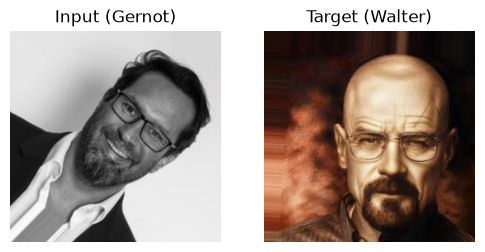

In [5]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader, random_split
from tqdm.auto import tqdm

SIZE = 256

def load_rgb_image(path):
    # OpenCV loads BGR, so convert to RGB, resize, and scale pixels to [0, 1]
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (SIZE, SIZE), interpolation=cv2.INTER_AREA)
    return image.astype(np.float32) / 255.0

input_files = sorted(Path("./data/heisenberg_heisenberg/gernot").iterdir())
target_files = sorted(Path("./data/heisenberg_heisenberg/walter").iterdir())
print(f"Input images: {len(input_files)}, target images: {len(target_files)}")

# Images as tensors in the shape N x C x H x W (PyTorch's channels-first format)
inputs = torch.from_numpy(np.stack([load_rgb_image(p) for p in tqdm(input_files)])).permute(0, 3, 1, 2)
targets = torch.from_numpy(np.stack([load_rgb_image(p) for p in tqdm(target_files)])).permute(0, 3, 1, 2)

# Split the 50 pairs: 40 for training, 10 for validation
dataset = TensorDataset(inputs, targets)
train_set, val_set = random_split(dataset, [40, 10], generator=torch.Generator().manual_seed(1))
print(f"Training pairs: {len(train_set)}, validation pairs: {len(val_set)}")

# Show one example pair
fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(inputs[0].permute(1, 2, 0)); axes[0].set_title("Input (Gernot)")
axes[1].imshow(targets[0].permute(1, 2, 0)); axes[1].set_title("Target (Walter)")
for ax in axes: ax.axis("off")
plt.show()

### CNN autoencoder
The encoder uses convolution layers to find important features (edges, shapes) and pooling layers to shrink the image. The decoder uses upsampling to grow it back to full size.

In [6]:
class DomainAdaptationAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        # Encoder: 256x256 -> 32x32, three times "find features, then halve the size"
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 256 -> 128
            nn.Conv2d(32, 8, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 128 -> 64
            nn.Conv2d(8, 8, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 64 -> 32
        )
        # Decoder: 32x32 -> 256x256, three times "process, then double the size"
        self.decoder = nn.Sequential(
            nn.Conv2d(8, 8, kernel_size=3, padding=1), nn.ReLU(),
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),       # 32 -> 64
            nn.Conv2d(8, 8, kernel_size=3, padding=1), nn.ReLU(),
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),       # 64 -> 128
            nn.Conv2d(8, 32, kernel_size=3, padding=1), nn.ReLU(),
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),       # 128 -> 256
            nn.Conv2d(32, 3, kernel_size=3, padding=1), nn.Sigmoid(),                 # back to RGB in [0, 1]
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))

model = DomainAdaptationAutoencoder().to(device)
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters()))

DomainAdaptationAutoencoder(
  (encoder): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(8, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (decoder): Sequential(
    (0): Conv2d(8, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Upsample(scale_factor=2.0, mode='bilinear')
    (3): Conv2d(8, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): Upsample(scale_factor=2.0, mode='bilinear')
    (6): Conv2d(8, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): Upsample(scal

### Training with loss monitoring
I train with shuffled mini-batches of 4 image pairs. Instead of a fixed number of epochs, I use early stopping: training stops when the validation loss has not improved for 15 epochs. The model with the lowest validation loss is kept. The maximum is 200 epochs.

Epoch 010: train=0.06539, val=0.06513
Epoch 020: train=0.06404, val=0.06412
Epoch 030: train=0.06260, val=0.06343
Epoch 040: train=0.06198, val=0.06299
Epoch 050: train=0.06142, val=0.06349
Early stop at epoch 51
Best validation loss: 0.06295 at epoch 36
Training time: 13.2 s


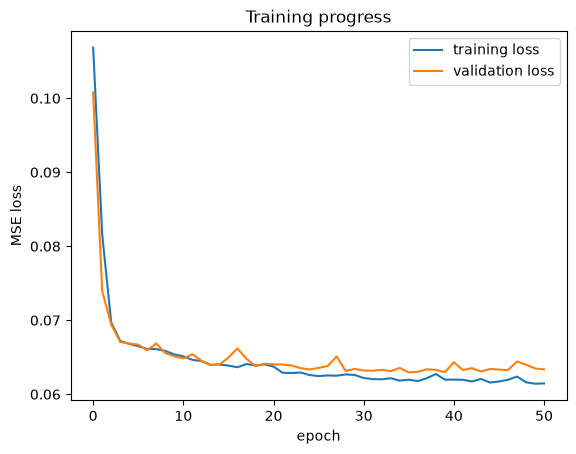

In [7]:
import copy, time

train_loader = DataLoader(train_set, batch_size=4, shuffle=True)   # shuffled mini-batches
val_loader = DataLoader(val_set, batch_size=4, shuffle=False)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

MAX_EPOCHS = 200
PATIENCE = 15          # stop if validation loss does not improve for 15 epochs
best_val, best_state, wait = float("inf"), None, 0
history = {"train": [], "val": []}
start = time.perf_counter()

for epoch in range(MAX_EPOCHS):
    # Training: learn from the 40 training pairs
    model.train()
    train_loss = 0.0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * x.size(0)
    train_loss /= len(train_set)

    # Validation: only measure on the 10 unseen pairs, no learning
    model.eval()
    val_loss = 0.0
    with torch.inference_mode():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)
            val_loss += criterion(model(x), y).item() * x.size(0)
    val_loss /= len(val_set)

    history["train"].append(train_loss)
    history["val"].append(val_loss)

    # Early stopping: remember the best model, stop when it stops improving
    if val_loss < best_val:
        best_val, best_state, wait = val_loss, copy.deepcopy(model.state_dict()), 0
    else:
        wait += 1
        if wait >= PATIENCE:
            print(f"Early stop at epoch {epoch + 1}")
            break

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch + 1:03d}: train={train_loss:.5f}, val={val_loss:.5f}")

model.load_state_dict(best_state)
print(f"Best validation loss: {best_val:.5f} at epoch {int(np.argmin(history['val'])) + 1}")
print(f"Training time: {time.perf_counter() - start:.1f} s")

# Loss curves
plt.plot(history["train"], label="training loss")
plt.plot(history["val"], label="validation loss")
plt.xlabel("epoch"); plt.ylabel("MSE loss"); plt.legend(); plt.title("Training progress")
plt.show()

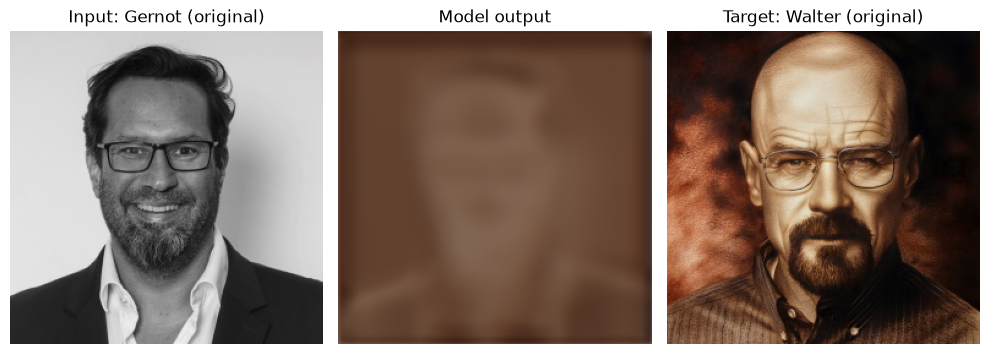

In [8]:
test_image = load_rgb_image("./data/heisenberg_heisenberg/gernot-heisenberg-original.jpg")
target_image = load_rgb_image("./data/heisenberg_heisenberg/walter-white-original.jpg")
test_tensor = torch.from_numpy(test_image).permute(2, 0, 1).unsqueeze(0).to(device)

model.eval()
with torch.inference_mode():
    prediction = model(test_tensor).squeeze(0).permute(1, 2, 0).cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
for ax, img, title in zip(axes, [test_image, prediction, target_image],
                          ["Input: Gernot (original)", "Model output", "Target: Walter (original)"]):
    ax.imshow(img); ax.set_title(title); ax.axis("off")
plt.tight_layout()
plt.show()

### Improvement: matched augmentation
The output above is a brown blur, close to the average of all Walter images. The reason: the 50 Gernot and 50 Walter images were augmented separately. The rotation and position of input and target do not match, so the network cannot learn which part of Gernot's face becomes which part of Walter's face. With MSE loss, the best it can do is predict the average target.

Fix: I create new pairs from the two original images and apply the same random transformation to both. Then every pair matches.

Matched pairs: 60, training: 48, validation: 12


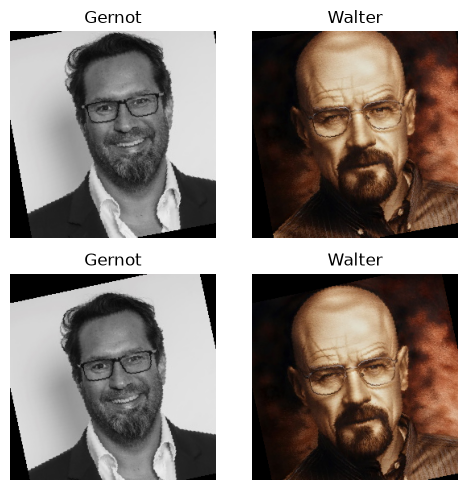

In [9]:
from PIL import Image
from torchvision.transforms import v2
from torchvision.transforms import functional as TF

# Load both originals at the same size
gernot = Image.open("./data/heisenberg_heisenberg/gernot-heisenberg-original.jpg").convert("RGB").resize((SIZE, SIZE))
walter = Image.open("./data/heisenberg_heisenberg/walter-white-original.jpg").convert("RGB").resize((SIZE, SIZE))

# Random rotation, shift, zoom and flip
augmentation = v2.Compose([
    v2.RandomAffine(degrees=20, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    v2.RandomHorizontalFlip(p=0.5),
])

torch.manual_seed(1)
pair_inputs, pair_targets = [], []
for _ in range(60):
    # Passing both images in one call applies the SAME random transformation to both
    g_aug, w_aug = augmentation(gernot, walter)
    pair_inputs.append(TF.pil_to_tensor(g_aug).float() / 255.0)
    pair_targets.append(TF.pil_to_tensor(w_aug).float() / 255.0)

matched = TensorDataset(torch.stack(pair_inputs), torch.stack(pair_targets))
train_set, val_set = random_split(matched, [48, 12], generator=torch.Generator().manual_seed(1))
print(f"Matched pairs: {len(matched)}, training: {len(train_set)}, validation: {len(val_set)}")

# Show two pairs to check that they match
fig, axes = plt.subplots(2, 2, figsize=(5, 5))
for row in range(2):
    axes[row, 0].imshow(pair_inputs[row].permute(1, 2, 0)); axes[row, 0].set_title("Gernot")
    axes[row, 1].imshow(pair_targets[row].permute(1, 2, 0)); axes[row, 1].set_title("Walter")
for ax in axes.flat: ax.axis("off")
plt.tight_layout(); plt.show()

In [10]:
model = DomainAdaptationAutoencoder().to(device)   # start again from random weights

Epoch 010: train=0.04396, val=0.04570
Epoch 020: train=0.02997, val=0.03085
Epoch 030: train=0.02237, val=0.02262
Epoch 040: train=0.01765, val=0.01967
Epoch 050: train=0.01576, val=0.01714
Epoch 060: train=0.01482, val=0.01615
Epoch 070: train=0.01418, val=0.01540
Epoch 080: train=0.01303, val=0.01476
Epoch 090: train=0.01267, val=0.01433
Epoch 100: train=0.01234, val=0.01391
Epoch 110: train=0.01169, val=0.01343
Epoch 120: train=0.01122, val=0.01291
Epoch 130: train=0.01109, val=0.01274
Epoch 140: train=0.01160, val=0.01278
Epoch 150: train=0.01033, val=0.01187
Epoch 160: train=0.01033, val=0.01194
Epoch 170: train=0.01029, val=0.01187
Epoch 180: train=0.01001, val=0.01159
Epoch 190: train=0.00979, val=0.01119
Epoch 200: train=0.00945, val=0.01118
Epoch 210: train=0.00943, val=0.01100
Epoch 220: train=0.00924, val=0.01083
Epoch 230: train=0.00998, val=0.01094
Epoch 240: train=0.00894, val=0.01062
Epoch 250: train=0.00960, val=0.01100
Epoch 260: train=0.00888, val=0.01059
Early stop a

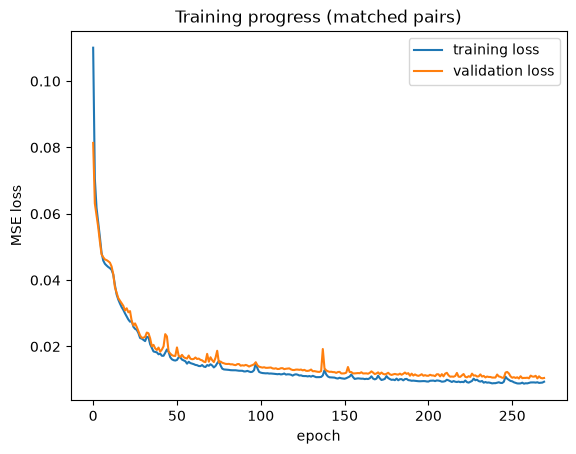

In [11]:
import copy, time

train_loader = DataLoader(train_set, batch_size=4, shuffle=True)   # shuffled mini-batches
val_loader = DataLoader(val_set, batch_size=4, shuffle=False)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

MAX_EPOCHS = 300
PATIENCE = 15          # stop if validation loss does not improve for 15 epochs
best_val, best_state, wait = float("inf"), None, 0
history = {"train": [], "val": []}
start = time.perf_counter()

for epoch in range(MAX_EPOCHS):
    # Training: learn from the training pairs
    model.train()
    train_loss = 0.0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * x.size(0)
    train_loss /= len(train_set)

    # Validation: only measure on the unseen pairs, no learning
    model.eval()
    val_loss = 0.0
    with torch.inference_mode():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)
            val_loss += criterion(model(x), y).item() * x.size(0)
    val_loss /= len(val_set)

    history["train"].append(train_loss)
    history["val"].append(val_loss)

    # Early stopping: remember the best model, stop when it stops improving
    if val_loss < best_val:
        best_val, best_state, wait = val_loss, copy.deepcopy(model.state_dict()), 0
    else:
        wait += 1
        if wait >= PATIENCE:
            print(f"Early stop at epoch {epoch + 1}")
            break

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch + 1:03d}: train={train_loss:.5f}, val={val_loss:.5f}")

model.load_state_dict(best_state)
print(f"Best validation loss: {best_val:.5f} at epoch {int(np.argmin(history['val'])) + 1}")
print(f"Training time: {time.perf_counter() - start:.1f} s")

# Loss curves
plt.plot(history["train"], label="training loss")
plt.plot(history["val"], label="validation loss")
plt.xlabel("epoch"); plt.ylabel("MSE loss"); plt.legend(); plt.title("Training progress (matched pairs)")
plt.show()

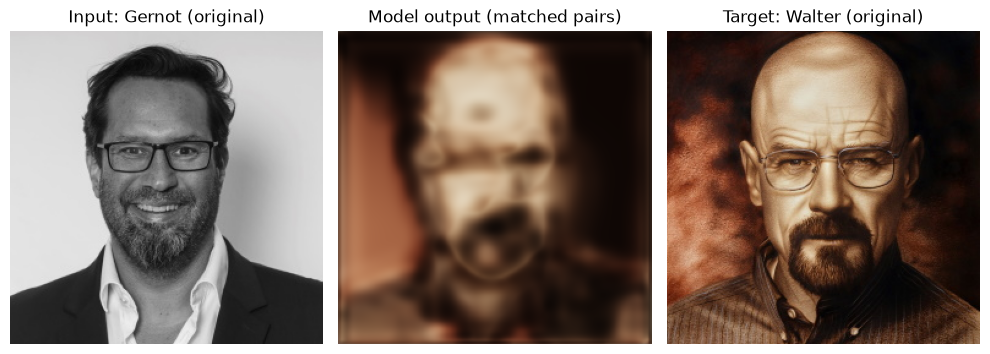

In [12]:
test_image = load_rgb_image("./data/heisenberg_heisenberg/gernot-heisenberg-original.jpg")
target_image = load_rgb_image("./data/heisenberg_heisenberg/walter-white-original.jpg")
test_tensor = torch.from_numpy(test_image).permute(2, 0, 1).unsqueeze(0).to(device)

model.eval()
with torch.inference_mode():
    prediction = model(test_tensor).squeeze(0).permute(1, 2, 0).cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
for ax, img, title in zip(axes, [test_image, prediction, target_image],
                          ["Input: Gernot (original)", "Model output (matched pairs)", "Target: Walter (original)"]):
    ax.imshow(img); ax.set_title(title); ax.axis("off")
plt.tight_layout()
plt.show()

### Results with matched pairs

| | Separate augmentation | Matched augmentation |
|---|---|---|
| Best validation loss | 0.063 | 0.010 |
| Output | Brown blur (average image) | Recognizable Walter layout |

With matched pairs, the output shows Walter's typical features at the right positions: the bald head, the dark glasses band, the goatee and the dark shoulders. The colours match Walter's picture. Training and validation loss stay close together, so the model does not overfit. Early stopping ended training at about epoch 270.

The output is still blurry. The bottleneck (8 channels of 32 x 32) is very small, so fine details such as wrinkles, eyes and glasses frames are lost. A larger network would give a sharper image but would need more training time.

**Conclusion:** For domain adaptation, the input and target pairs must match. When they are augmented separately, the network can only learn the average target image. When the same transformation is applied to both images, the network learns which part of the input face becomes which part of the target face.